In [18]:
#Q1

import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text = """Football is my favourite sport. I enjoy watching football matches
with my friends. Football requires teamwork, speed, and skill.
Players train hard to improve their performance. Football teaches
discipline and brings people together."""

clean_text=re.sub(r'[^\w\s]', '', text.lower())
print("Clean Text:")
print(clean_text)

sentences=sent_tokenize(text)
words=word_tokenize(clean_text)

print("\nSentences:")
print(sentences)

print("\nWords:")
print(words)

print("\nUsing split():")
print(clean_text.split())

print("\nUsing word_tokenize():")
print(word_tokenize(text.lower()))

stop_words = set(stopwords.words('english'))
filtered_words=[]

for word in words:
    if word not in stop_words:
        filtered_words.append(word)

print("\nWords after removing stopwords:")
print(filtered_words)

frequency=FreqDist(filtered_words)

print("\nWord Frequency Distribution:")
print(frequency.most_common())


[nltk_data] Error loading punkt: <urlopen error [WinError 10054] An
[nltk_data]     existing connection was forcibly closed by the remote
[nltk_data]     host>
[nltk_data] Error loading punkt_tab: <urlopen error [WinError 10054]
[nltk_data]     An existing connection was forcibly closed by the
[nltk_data]     remote host>


Clean Text:
football is my favourite sport i enjoy watching football matches
with my friends football requires teamwork speed and skill
players train hard to improve their performance football teaches
discipline and brings people together

Sentences:
['Football is my favourite sport.', 'I enjoy watching football matches\nwith my friends.', 'Football requires teamwork, speed, and skill.', 'Players train hard to improve their performance.', 'Football teaches\ndiscipline and brings people together.']

Words:
['football', 'is', 'my', 'favourite', 'sport', 'i', 'enjoy', 'watching', 'football', 'matches', 'with', 'my', 'friends', 'football', 'requires', 'teamwork', 'speed', 'and', 'skill', 'players', 'train', 'hard', 'to', 'improve', 'their', 'performance', 'football', 'teaches', 'discipline', 'and', 'brings', 'people', 'together']

Using split():
['football', 'is', 'my', 'favourite', 'sport', 'i', 'enjoy', 'watching', 'football', 'matches', 'with', 'my', 'friends', 'football', 'requires', '

[nltk_data] Error loading stopwords: <urlopen error [WinError 10054]
[nltk_data]     An existing connection was forcibly closed by the
[nltk_data]     remote host>


In [8]:
#Q2

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

words=re.findall(r'\b[a-zA-Z]+\b', text.lower())
print("Alphabetic Words:")
print(words)

stop_words=set(stopwords.words('english'))
filtered_words=[]

for word in words:
    if word not in stop_words:
        filtered_words.append(word)

print("\nAfter Removing Stopwords:")
print(filtered_words)

stemmer=PorterStemmer()
stemmed_words=[]

for word in filtered_words:
    stemmed_words.append(stemmer.stem(word))

print("\nStemmed Words:")
print(stemmed_words)

lemmatizer=WordNetLemmatizer()
lemmatized_words=[]

for word in filtered_words:
    lemmatized_words.append(lemmatizer.lemmatize(word))

print("\nLemmatized Words:")
print(lemmatized_words)

print("\nComparison:")
print("Stemming:",stemmed_words)
print("Lemmatization:",lemmatized_words)


[nltk_data] Error loading stopwords: <urlopen error [WinError 10054]
[nltk_data]     An existing connection was forcibly closed by the
[nltk_data]     remote host>
[nltk_data] Error loading wordnet: <urlopen error [WinError 10054] An
[nltk_data]     existing connection was forcibly closed by the remote
[nltk_data]     host>


Alphabetic Words:
['football', 'is', 'my', 'favourite', 'sport', 'i', 'enjoy', 'watching', 'football', 'matches', 'with', 'my', 'friends', 'football', 'requires', 'teamwork', 'speed', 'and', 'skill', 'players', 'train', 'hard', 'to', 'improve', 'their', 'performance', 'football', 'teaches', 'discipline', 'and', 'brings', 'people', 'together']

After Removing Stopwords:
['football', 'favourite', 'sport', 'enjoy', 'watching', 'football', 'matches', 'friends', 'football', 'requires', 'teamwork', 'speed', 'skill', 'players', 'train', 'hard', 'improve', 'performance', 'football', 'teaches', 'discipline', 'brings', 'people', 'together']

Stemmed Words:
['footbal', 'favourit', 'sport', 'enjoy', 'watch', 'footbal', 'match', 'friend', 'footbal', 'requir', 'teamwork', 'speed', 'skill', 'player', 'train', 'hard', 'improv', 'perform', 'footbal', 'teach', 'disciplin', 'bring', 'peopl', 'togeth']

Lemmatized Words:
['football', 'favourite', 'sport', 'enjoy', 'watching', 'football', 'match', 'friend'

[nltk_data] Error loading omw-1.4: <urlopen error [WinError 10054] An
[nltk_data]     existing connection was forcibly closed by the remote
[nltk_data]     host>


In [9]:
#Q3

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts=[
    "Football is an exciting sport and football players train hard",
    "Artificial intelligence helps computers learn and solve problems",
    "Healthy food gives energy and keeps the body healthy"
]

count_vectorizer=CountVectorizer()
bow_matrix=count_vectorizer.fit_transform(texts)

print("Bag of Words:")
print(count_vectorizer.get_feature_names_out())
print(bow_matrix.toarray())

tfidf_vectorizer=TfidfVectorizer()
tfidf_matrix=tfidf_vectorizer.fit_transform(texts)

print("\nTF-IDF Feature Names:")
print(tfidf_vectorizer.get_feature_names_out())

print("\nTF-IDF Matrix:")
print(tfidf_matrix.toarray().round(3))

feature_names=tfidf_vectorizer.get_feature_names_out()

for i in range(len(texts)):
    scores=tfidf_matrix[i].toarray()[0]
    top_indices=scores.argsort()[::-1][:3]

    print("\nText",i + 1,"Top 3 Keywords:")
    for index in top_indices:
        print(feature_names[index],":",round(scores[index],3))


Bag of Words:
['an' 'and' 'artificial' 'body' 'computers' 'energy' 'exciting' 'food'
 'football' 'gives' 'hard' 'healthy' 'helps' 'intelligence' 'is' 'keeps'
 'learn' 'players' 'problems' 'solve' 'sport' 'the' 'train']
[[1 1 0 0 0 0 1 0 2 0 1 0 0 0 1 0 0 1 0 0 1 0 1]
 [0 1 1 0 1 0 0 0 0 0 0 0 1 1 0 0 1 0 1 1 0 0 0]
 [0 1 0 1 0 1 0 1 0 1 0 2 0 0 0 1 0 0 0 0 0 1 0]]

TF-IDF Feature Names:
['an' 'and' 'artificial' 'body' 'computers' 'energy' 'exciting' 'food'
 'football' 'gives' 'hard' 'healthy' 'helps' 'intelligence' 'is' 'keeps'
 'learn' 'players' 'problems' 'solve' 'sport' 'the' 'train']

TF-IDF Matrix:
[[0.297 0.175 0.    0.    0.    0.    0.297 0.    0.594 0.    0.297 0.
  0.    0.    0.297 0.    0.    0.297 0.    0.    0.297 0.    0.297]
 [0.    0.218 0.369 0.    0.369 0.    0.    0.    0.    0.    0.    0.
  0.369 0.369 0.    0.    0.369 0.    0.369 0.369 0.    0.    0.   ]
 [0.    0.184 0.    0.311 0.    0.311 0.    0.311 0.    0.311 0.    0.622
  0.    0.    0.    0.311 0.    0. 

In [10]:
#Q4

import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text1="""Artificial intelligence allows computers to learn from data.
AI is used in healthcare, education, and robotics.
Machine learning helps systems make predictions.
AI can automate many tasks."""

text2="""Blockchain is a digital ledger that stores transactions.
It provides security and transparency.
Blockchain is used in cryptocurrency and finance.
It records information across multiple computers."""

clean1=re.sub(r'[^\w\s]', '', text1.lower())
clean2=re.sub(r'[^\w\s]', '', text2.lower())

words1=clean1.split()
words2=clean2.split()

print("Tokens of Text 1:")
print(words1)

print("\nTokens of Text 2:")
print(words2)

set1=set(words1)
set2=set(words2)

common_words=set1.intersection(set2)
all_words=set1.union(set2)

jaccard=len(common_words)/len(all_words)

print("\nCommon Words:",common_words)
print("Jaccard Similarity:",round(jaccard,3))

vectorizer=TfidfVectorizer()
matrix=vectorizer.fit_transform([clean1,clean2])

cosine=cosine_similarity(matrix[0:1],matrix[1:2])

print("Cosine Similarity:",round(cosine[0][0], 3))

print("\nAnalysis:")
print("Jaccard measures the overlap between unique words.")
print("Cosine similarity compares the TF-IDF word vectors.")
print("Both scores are low when the texts discuss different topics.")


Tokens of Text 1:
['artificial', 'intelligence', 'allows', 'computers', 'to', 'learn', 'from', 'data', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'robotics', 'machine', 'learning', 'helps', 'systems', 'make', 'predictions', 'ai', 'can', 'automate', 'many', 'tasks']

Tokens of Text 2:
['blockchain', 'is', 'a', 'digital', 'ledger', 'that', 'stores', 'transactions', 'it', 'provides', 'security', 'and', 'transparency', 'blockchain', 'is', 'used', 'in', 'cryptocurrency', 'and', 'finance', 'it', 'records', 'information', 'across', 'multiple', 'computers']

Common Words: {'computers', 'and', 'used', 'in', 'is'}
Jaccard Similarity: 0.116
Cosine Similarity: 0.131

Analysis:
Jaccard measures the overlap between unique words.
Cosine similarity compares the TF-IDF word vectors.
Both scores are low when the texts discuss different topics.


In [13]:
pip install nltk textblob wordcloud matplotlib

Note: you may need to restart the kernel to use updated packages.



Review: This product is amazing and works perfectly.
Polarity: 0.8
Subjectivity: 0.95
Sentiment: Positive

Review: The quality is excellent and I really love it.
Polarity: 0.75
Subjectivity: 0.8
Sentiment: Positive

Review: The product is terrible and stopped working.
Polarity: -1.0
Subjectivity: 1.0
Sentiment: Negative

Review: Very bad quality and a waste of money.
Polarity: -0.55
Subjectivity: 0.43
Sentiment: Negative

Review: The product is okay and works as expected.
Polarity: 0.2
Subjectivity: 0.45
Sentiment: Positive


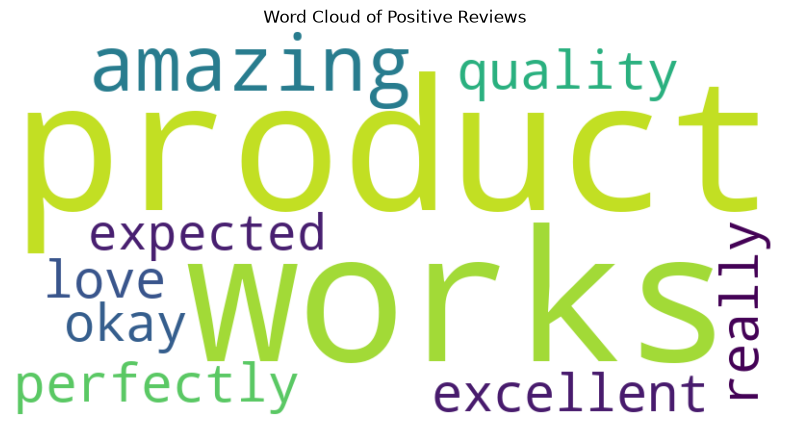

In [16]:
#Q5

from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews=[
    "This product is amazing and works perfectly.",
    "The quality is excellent and I really love it.",
    "The product is terrible and stopped working.",
    "Very bad quality and a waste of money.",
    "The product is okay and works as expected."
]

positive_reviews=[]

for review in reviews:
    blob=TextBlob(review)

    polarity=blob.sentiment.polarity
    subjectivity=blob.sentiment.subjectivity

    if polarity>0:
        sentiment="Positive"
    elif polarity<0:
        sentiment="Negative"
    else:
        sentiment="Neutral"

    if sentiment=="Positive":
        positive_reviews.append(review)

    print("\nReview:",review)
    print("Polarity:",round(polarity, 2))
    print("Subjectivity:",round(subjectivity, 2))
    print("Sentiment:",sentiment)

if len(positive_reviews)>0:
    positive_text=" ".join(positive_reviews)
    
    wordcloud=WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(positive_text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()

else:
    print("No positive reviews found.")

In [17]:
#Q6

import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """
Technology has changed the way people live and work.
Computers help people solve problems and complete tasks.
Artificial intelligence helps computers learn from data.
Machine learning allows computers to find patterns.
Students use technology to study and learn new skills.
The internet connects people around the world.
Technology is useful in education healthcare and business.
Programming helps students build useful applications.
Computers can process information quickly and accurately.
New technology creates opportunities for learning and innovation.
Students should use technology responsibly and creatively.
Learning programming improves logical thinking and problem solving.
Artificial intelligence can help people make better decisions.
Technology continues to improve our daily lives.
"""

tokenizer=Tokenizer()
tokenizer.fit_on_texts([text])

total_words=len(tokenizer.word_index) + 1
sequences=[]

for line in text.lower().split('.'):
    encoded=tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(encoded)):
        sequences.append(encoded[:i + 1])

max_length=max(len(seq) for seq in sequences)
sequences=pad_sequences(sequences, maxlen=max_length)

X=sequences[:,:-1]
y=sequences[:,-1]

model = Sequential()
model.add(Embedding(total_words,50,input_length=max_length-1))
model.add(LSTM(100))
model.add(Dense(total_words,activation='softmax'))

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.fit(X, y, epochs=100, verbose=0)
print("Model training completed!")

def generate_text(seed_text,next_words):
    for i in range(next_words):
        encoded=tokenizer.texts_to_sequences([seed_text])[0]
        encoded=pad_sequences([encoded],maxlen=max_length-1)

        prediction=model.predict(encoded,verbose=0)
        predicted_index=np.argmax(prediction,axis=1)[0]

        predicted_word=""

        for word, index in tokenizer.word_index.items():
            if index==predicted_index:
                predicted_word=word
                break

        if predicted_word=="":
            break
        seed_text=seed_text + " " + predicted_word
    return seed_text
    
print("\nGenerated Text:")
print(generate_text("technology",10))
print(generate_text("students",10))
print(generate_text("artificial intelligence",10))

Model training completed!

Generated Text:
technology is useful in education healthcare and business skills skills skills
students use technology to study and learn new skills skills skills
artificial intelligence can help people make better decisions decisions decisions decisions decisions
